# 08 · Elasticsearch 基础、索引设计与 Java 操作（Elasticsearch01）


## 本章来源与学习路线

依据百度网盘 `我的资源/day08-Elasticsearch01/PPT/Elasticsearch01.pptx` 整理，原课件与网盘预览均为 **63 页，无隐藏页**。关键截图已内嵌，离线可读。

| 课件范围 | 本篇知识 |
| --- | --- |
| 第 1—11 页 | Elasticsearch、Lucene、Elastic Stack 的职责 |
| 第 13—20 页 | 倒排索引、IK 分词器、扩展词典 |
| 第 22—35 页 | 文档模型、Mapping、索引库操作 |
| 第 38—43 页 | 文档 CRUD、全量与局部更新、Bulk |
| 第 46—63 页 | 商品索引设计、RestHighLevelClient、Java 索引与文档 API |

**版本基线**：课程使用 Elasticsearch / IK / Java High Level REST Client **7.12.1**。文中的 REST 路径、Java 类与包名按这条版本线组织；Java 示例使用 Java 8 可用的写法。课件中“最新版本 8.x”“多数企业使用 8 以下版本”是当时的背景，不能当作现在的版本或市场结论。

标为“整理示例”的代码修正了课件的省略、占位符与语法问题；标为“补充”的内容用于解释工程边界。没有运行 Elasticsearch、Kibana、IK 或 Java 工程，以下示例应在匹配版本的学习环境验证。

学习顺序：**为什么要搜索引擎 → 怎样建立倒排索引 → 怎样分词 → 怎样设计字段 → REST 操作 → Java 操作 → 批量导入与同步**。


## 1. Elasticsearch 与 Lucene

商品搜索需要关键词匹配、相关性排序、条件筛选；日志分析需要在大量文本中快速查找与聚合。Elasticsearch（简称 ES）把搜索能力做成可通过 HTTP 调用的分布式服务。（课件第 1—9 页）

| 对象 | 是什么 | 解决什么问题 |
| --- | --- | --- |
| Lucene | Java 搜索引擎类库 | 文本分析、倒排索引、检索与评分 |
| Elasticsearch | 基于 Lucene 构建的搜索与分析服务 | REST API、集群管理、分片、复制、分布式查询 |
| Solr | 另一种基于 Lucene 的搜索服务 | 搜索与索引管理；课件用它作为同领域对照 |
| Splunk | 日志分析与可观测性平台 | 课件中的商业产品对照 |

Lucene 是嵌入程序的库；ES 管理可访问的服务。ES 的“分布式”表示数据可以分成多个**分片**，分布到不同节点；**副本**保存分片的复制数据，用于提高可用性并承担读请求。增加节点是否提升性能，还取决于分片设计、资源和查询负载。

商品系统通常用 MySQL 保存订单、库存等交易事实，用 ES 保存可搜索的商品数据。二者分工由查询需求决定，ES 中的搜索结果不能直接作为扣库存的交易依据。


## 2. ELK 与数据流

日志来自多台机器时，需要收集、处理、检索和展示，单独的搜索引擎不覆盖整条流程。（课件第 10—11 页）

| 组件 | 职责 |
| --- | --- |
| Beats | 轻量采集器，收集日志、指标等 |
| Logstash | 接收、解析、转换与转发数据 |
| Elasticsearch | 建立索引，执行搜索与聚合 |
| Kibana | 可视化、仪表盘、管理界面与 Dev Tools |

```text
应用日志 / 主机指标
        ↓ Beats 采集
        ↓ Logstash 解析与转换（可选）
        ↓ Elasticsearch 索引与检索
        ↓ Kibana 图表与查询界面
```

ELK 最初指 Elasticsearch、Logstash、Kibana；加入 Beats 等组件后通常统称 Elastic Stack。实际链路可以直接由采集器写入 ES，不必强制经过每个组件。

本章用 Kibana Dev Tools 编写 REST 请求，Kibana 会把请求发给它配置的 ES 服务；数据实际存储在 ES。


## 3. 学习环境与版本配套

先确认服务地址与插件版本，再执行课件 API。资料目录可见 `es.tar`、`kibana.tar`、`elasticsearch-analysis-ik-7.12.1.zip` 和展开的 `ik/`；文件名只能证明资料存在，不能替代运行版本检查。（课件第 17—18、47 页）

| 对象 | 学习环境中要确认的内容 |
| --- | --- |
| Elasticsearch | 运行版本 7.12.1；HTTP 端口通常为 9200 |
| Kibana | 使用配套版本，能够连通 ES；Web 端口通常为 5601 |
| IK 插件 | 插件版本匹配 ES，安装到 ES 的 plugins 目录 |
| Java 客户端 | 依赖使用 7.12.1，连接真实可达的 ES HTTP 地址 |

在 Kibana Dev Tools 中查看 ES 信息：

```http
GET /
```

查看加载的插件（补充）：

```http
GET /_cat/plugins?v
```

插件目录结构应类似：

```text
elasticsearch/
└── plugins/
    └── ik/
        ├── plugin-descriptor.properties
        ├── elasticsearch-analysis-ik-7.12.1.jar
        ├── 其他依赖 jar
        └── config/
            ├── IKAnalyzer.cfg.xml
            └── 词典文件
```

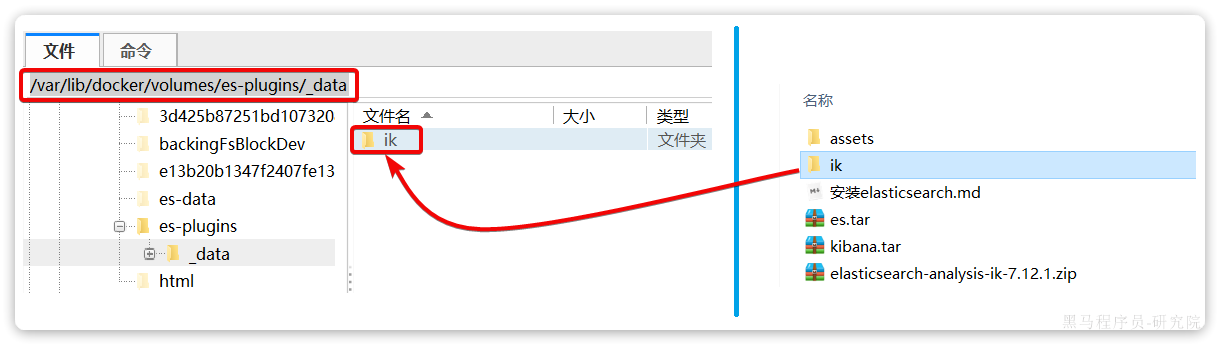

截图中的 Linux 路径是课件环境示意。Docker 部署时应核对宿主机目录与容器目录的挂载关系，不能把截图路径直接当成本机路径。安装插件后按版本要求重启节点，并用 `_analyze` 验证；多节点集群需要在相关节点保持插件与词典一致。


## 4. 正向查找与倒排索引

按商品 ID 查数据容易，按“内容含手机”查数据则需要把词与文档建立关系。（课件第 13—15 页）

| 文档 ID | 标题 |
| --- | --- |
| 1 | 小米手机 |
| 2 | 华为手机 |
| 3 | 华为小米充电器 |
| 4 | 小米手环 |

课件用“文档 ID → 文档内容”说明正向查找。若只存在 ID 索引，`WHERE title LIKE '%手机%'` 一般无法利用它定位文本，可能需要扫描候选行。**MySQL 并非只有课件所画的正向索引**：常见 B+ 树索引支持精确值与范围查询，也有全文索引；前导通配符查询的限制不能推广成“数据库查询都要扫描”。

倒排索引把方向反过来：

| 词条 | 包含该词条的文档 ID |
| --- | --- |
| 小米 | 1、3、4 |
| 手机 | 1、2 |
| 华为 | 2、3 |
| 充电器 | 3 |
| 手环 | 4 |

```text
写入：文档 → 分词 → 词条 → 记录词条对应的文档
检索：搜索文本 → 分词 → 查词条列表 → 合并候选 ID → 取文档并排序
```

表格是教学模型。Lucene 实际还可以记录词频、位置等信息，以支持相关性评分和短语匹配。


## 5. 分词不决定查询的 AND / OR

“华为手机”拆成“华为”“手机”后，命中什么文档还取决于查询逻辑。（课件第 14 页）

```text
华为 → {2, 3}
手机 → {1, 2}

OR：命中任一词 → 并集 {1, 2, 3}
AND：两个词都命中 → 交集 {2}
```

课件得到 ID 1、2、3，展示的是并集效果，不能理解成所有全文查询都会得到这三个文档。全文 `match` 查询通常默认采用 OR，可配置 AND；短语查询还会考虑词条顺序与位置。

**分词器负责把文本变成词条；查询 DSL 负责组合匹配条件；评分负责对命中的文档排序。** “能命中”与“排在前面”是两个问题。

具体搜索 DSL 放到后续搜索章节；本章先保证写入与查询时能够生成合适的词条。


## 6. Analyzer 与 IK 的两种模式

中文没有天然的空格分隔，逐字切分可能丢失“程序员”等词的语义。Analyzer（分析器）把文本变成可检索的 token，写入索引和分析搜索词时都会使用。（课件第 17—20 页）

| 分析器 | 特点 | 适用判断 |
| --- | --- | --- |
| standard | ES 内置标准分析器；中文常呈现单字切分 | 用来观察默认分析结果 |
| ik_smart | IK 较粗粒度切分 | 词条较少，观察整体词语识别 |
| ik_max_word | IK 较细粒度切分，可能生成重叠词条 | 需要覆盖更多组合时评估 |

在 Dev Tools 中分别执行：

```http
POST /_analyze
{
  "analyzer": "standard",
  "text": "黑马程序员学习java太棒了"
}
```

```http
POST /_analyze
{
  "analyzer": "ik_smart",
  "text": "黑马程序员学习java太棒了"
}
```

```http
POST /_analyze
{
  "analyzer": "ik_max_word",
  "text": "黑马程序员学习java太棒了"
}
```

观察 `tokens` 中的 `token`、`position` 和起止位置。实际切分结果受插件版本与词典影响，不能只凭名称推断。

更细的分词可能扩大召回，同时增加索引体积和不相关命中。商品名称可评估“写入用 ik_max_word、搜索用 ik_smart”的组合，但要通过真实搜索词验证效果。


## 7. IK 扩展词典

品牌、课程名、新词未被识别时，可以把业务词加入 IK 扩展词典。（课件第 19—20 页）

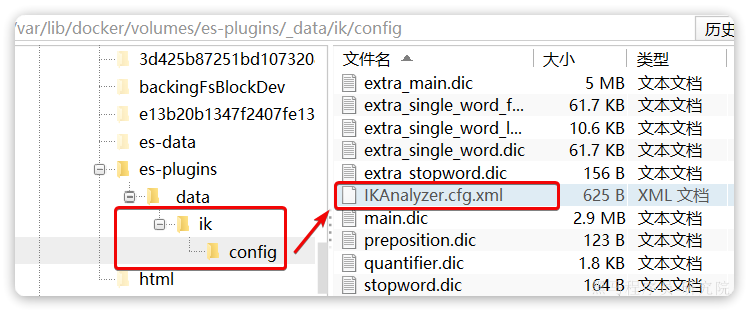

配置文件准确名称是 **`IKAnalyzer.cfg.xml`**。网盘资料的 `ik/config` 与课件截图一致；第 20 页文字中的 `IkAnalyzer.cfg.xml` 大小写不准确，Linux 上尤其要区分。

**课件配置整理**：在现有配置中设置或合并 `ext_dict`，不要用片段覆盖其他已有配置。

```xml
<?xml version="1.0" encoding="UTF-8"?>
<!DOCTYPE properties SYSTEM "http://java.sun.com/dtd/properties.dtd">
<properties>
  <comment>IK Analyzer 扩展配置</comment>
  <entry key="ext_dict">ext.dic</entry>
</properties>
```

在相应 config 目录创建 UTF-8 编码的 `ext.dic`，每行一个词：

```text
黑马程序员
天机学堂
```

```text
增加词条 → 按插件要求重新加载 / 重启 → _analyze 对照验证
                                            ↓
                              旧数据需要时重新索引
```

词典变更不会自动改写已经建立的倒排索引。若旧文档没有“天机学堂”这个词条，只更新词典并不能补出旧索引中的词条；要重新写入或重建索引。多节点使用相同词库，避免相同文本在不同节点产生不同分析结果。


## 8. 文档、字段、索引与 Mapping

ES 用 JSON 表达业务数据。一个商品可以是一个文档；相似用途的文档放在同一个索引中。（课件第 22—27 页）

| ES 概念 | 含义 | MySQL 的近似类比 |
| --- | --- | --- |
| Document，文档 | 一条 JSON 数据 | 行 Row |
| Field，字段 | JSON 的属性 | 列 Column |
| Index，索引 / 索引库 | 一组文档及其索引结构 | 表 Table |
| Mapping，映射 | 字段类型与索引方式等定义 | 表结构 Schema |
| Query DSL | JSON 风格的搜索条件语言 | SQL 的查询表达能力 |
| Term，词条 | 分析器产生或精确字段保留的检索单位 | 无完全对应概念 |

```json
{
  "id": "1",
  "name": "小米手机",
  "price": 349900
}
```

这里价格以**分**为单位，349900 分等于 3499 元；课件前面的概念示例与后面的商品表应区分单位。

类比只用于入门。Mapping 不会自动规定字段必填、建立外键，也不会提供 MySQL 那样的跨表事务语义。这里的 Index 是文档集合；“倒排索引”则指底层检索结构，两种“索引”不能混成一个概念。


## 9. Mapping 的字段类型

先确定字段怎样查询，再选类型。字段看起来都像字符串，索引行为仍可能完全不同。（课件第 29 页）

| 类型 | 用途 | 示例 / 注意 |
| --- | --- | --- |
| text | 分词后的全文检索 | 商品名称、介绍 |
| keyword | 精确匹配、排序、聚合 | 商品 ID、品牌、分类；不进行全文分词 |
| integer、long、short、byte | 整数 | 库存、销量、以分保存的价格；根据范围选择 |
| float、double | 浮点数 | 非精确金额的测量值等 |
| boolean | 布尔值 | 是否广告：true / false |
| date | 日期与时间 | 更新时间，输入格式应与 Mapping 匹配 |
| object | 层级对象 | `name.firstName` 等子字段 |
| ip（补充） | 专门的 IP 地址类型 | 需要 IP 范围能力时比通用 keyword 更合适 |

`text` 的「小米手机」可能生成“小米”“手机”等词；`keyword` 保存它的完整精确值。品牌筛选通常需要 `keyword`，将品牌一律映射成 `text` 容易造成筛选语义错误。

数组没有独立的 array 类型：`"score": [99.1, 99.5]` 可以由数值字段表示多值，同一字段的元素应与该字段类型兼容。缺省字段、`null`、空数组通常不会产生普通可检索的值。


## 10. index、_source 与 doc_values

“不参与搜索”“保留原始 JSON”“可以排序”是不同维度。（课件第 29、32 页；doc_values 为补充）

| 属性 / 结构 | 控制什么 | 不等于什么 |
| --- | --- | --- |
| `type` | 字段类型 | 不决定业务是否必填 |
| `analyzer` | text 写入时的分析器 | 不指定查询的 AND / OR |
| `search_analyzer` | text 搜索词的分析器 | 不改写已写入的词条 |
| `index` | 是否建立该字段的检索结构；默认 true | 不是是否保存字段 |
| `_source` | 保存文档原始 JSON，默认启用 | 不代替倒排索引 |
| `doc_values` | 面向排序、聚合等的列式存储 | 不代替 `_source` |
| `properties` | 对象的子字段定义 | 不定义对象数组成员间的隔离 |

`keyword`、数值、日期等支持的字段默认开启 doc_values；`text` 不支持普通 doc_values。

```json
{
  "properties": {
    "email": {
      "type": "keyword",
      "index": false
    },
    "image": {
      "type": "keyword",
      "index": false,
      "doc_values": false
    }
  }
}
```

`email` 不建立字段检索索引，但其 doc_values 默认仍在，可以用于适用的排序 / 聚合；`image` 只需要在结果中展示，所以额外关闭 doc_values。只要保留 `_source`，两者仍能从文档原始 JSON 中读取。

> 本篇按 **ES 7.12** 文档处理 `index:false`：不把它作为普通字段检索条件。新版本关于仅凭 doc_values 查询的能力不能无条件套进 7.12.1。关闭 doc_values 也不自动关闭已开启的字段检索索引。

课件中的 `"index": "false"` 整理为 JSON 布尔值 `"index": false`；本篇不用字符串形式表达布尔配置。


## 11. object 与对象数组的边界

对象字段通过 `properties` 递归定义，检索时通常用点路径访问子字段。（课件第 29、32 页）

```json
{
  "name": {
    "firstName": "云",
    "lastName": "赵"
  }
}
```

对应字段路径是 `name.firstName`、`name.lastName`。如果只是一个姓名对象，普通 object 就足够。

**补充：对象数组并不自动保留每个成员内部的配对关系。**

```json
{
  "users": [
    {"firstName": "张", "lastName": "三"},
    {"firstName": "李", "lastName": "四"}
  ]
}
```

普通 object 数组在检索结构中会扁平化，可能分别得到 firstName 的“张、李”和 lastName 的“三、四”。组合条件“张 + 四”可能跨成员命中。

商品的多个 SKU、多个地址等场景，若必须要求条件命中**同一个数组成员**，应评估 nested 类型与对应查询；它会增加索引和查询成本。本章的单个 `name` 对象不需要 nested。


## 12. 创建索引库与 Mapping

显式 Mapping 避免第一条数据的自动类型推断影响后续数据。创建索引前先装好 IK，否则会提示分析器不存在。（课件第 32 页）

**课件示例补全**：

```http
PUT /heima
{
  "mappings": {
    "properties": {
      "info": {
        "type": "text",
        "analyzer": "ik_smart"
      },
      "email": {
        "type": "keyword",
        "index": false
      },
      "name": {
        "type": "object",
        "properties": {
          "firstName": {
            "type": "keyword"
          },
          "lastName": {
            "type": "keyword"
          }
        }
      }
    }
  }
}
```

`mappings.properties` 定义顶层字段，`name.properties` 定义子字段。示例使用完整合法 JSON，不含课件中的省略注释和尾随逗号。

默认动态映射可能为未声明的新字段推断类型。稳定业务建议先列清字段；需要拒绝意外字段时，可评估 `dynamic: "strict"`（补充）。Mapping 定义了字段，并不要求每个文档都提供它。


## 13. 查看、删除与新增字段

索引库操作作用于整个文档集合，文档操作才作用于单条数据。（课件第 33—35 页）

| 目的 | 请求 |
| --- | --- |
| 查看索引信息 | `GET /heima` |
| 只看 Mapping（补充） | `GET /heima/_mapping` |
| 判断索引是否存在（补充） | `HEAD /heima` |
| 删除整个索引及其文档 | `DELETE /heima` |
| 增加字段 | `PUT /heima/_mapping` |

增加 `age` 字段：

```http
PUT /heima/_mapping
{
  "properties": {
    "age": {
      "type": "integer"
    }
  }
}
```

旧文档不会因此自动补上年龄；以后写入时才提供具体值。查看 Mapping 可以确认类型生效。

`DELETE /heima` 会删除索引内全部文档。它与 `DELETE /heima/_doc/1` 的作用范围不同；执行后继续文档示例前，应重新创建索引和 Mapping。


## 14. Mapping 变更与重建索引

课件“索引库和 Mapping 一旦创建无法修改”概括过宽。已有字段的类型与索引时分析方式通常不能直接改，但可以添加字段，也支持调整部分参数。（课件第 34 页）

| 变更 | 判断 |
| --- | --- |
| 新增 integer 类型的 age | 可通过更新 Mapping 添加 |
| 已有 price 从 keyword 改成 integer | 通常需新建索引并迁移 |
| 修改已有 text 的索引分析器 | 通常需重建，使旧文档重新分词 |
| 添加多字段 / 调整可更新参数 | 以相应版本参数规则为准；旧数据可能仍需重新处理 |
| 改分片等索引设置 | 不能用“Mapping 都不可改”判断，要看具体设置 |

**补充：重建流程**：

```text
设计 items_v2 的新 Mapping
        ↓
创建新索引 → 重写原始商品数据 / _reindex
        ↓
检查文档数、字段、搜索效果
        ↓
处理迁移期间的增量数据
        ↓
切换业务使用的索引别名
```

`_reindex` 从源索引的 `_source` 读取并写入新索引；不会替你完整复制目标 Mapping、保证业务增量同步或修正错误数据。新 Mapping 应预先创建。也可以直接从 MySQL 全量重建搜索数据。

别名是业务访问的逻辑名称；如果应用始终使用别名，可以切换它指向的新索引，避免在业务代码中到处改索引名。切换前必须处理增量遗漏与旧数据覆盖新数据的问题。


## 15. 写入文档与 _id

写入单个文档时，路径中的 ID 标识 ES 文档；JSON 中的业务 `id` 是普通字段，两者不会自动绑定。（课件第 38、41 页）

```http
POST /heima/_doc/1
{
  "info": "黑马程序员Java讲师",
  "email": "zy@itcast.cn",
  "name": {
    "firstName": "云",
    "lastName": "赵"
  },
  "age": 21
}
```

前提是已创建索引并添加 age Mapping。上面的 `_id` 是 `1`，文档里没有普通 `id` 字段。

| 写法 | 行为 |
| --- | --- |
| `POST /heima/_doc` | 自动生成文档 ID |
| `POST /heima/_doc/1` 或 `PUT /heima/_doc/1` | ID 不存在时创建；存在时完整替换 |
| `PUT /heima/_create/1`（补充） | 只允许创建，已有同 ID 时冲突 |

“新增文档”的课件示例本质上使用 index 操作，**重复同 ID 并不是再插入一条，而是替换原文档**。

商品同步适合用稳定的业务商品 ID 作为 `_id`，同时在 JSON 保存 `"id": "商品ID"`。这有助于重复写入定位同一条数据，也避免前端处理超出安全整数范围的长整型 ID 时丢失精度。


## 16. 按 ID 查询与删除文档

按 ID 获取文档直接使用 `_doc`，不需要编写全文搜索条件。（课件第 39 页）

```http
GET /heima/_doc/1
```

成功结果通常包含 `_index`、`_id`、`found: true` 与 `_source`。文档不存在时返回未找到结果，客户端应区分“没有这条数据”和连接 / 权限异常。

```http
DELETE /heima/_doc/1
```

这里删除的是 ID 为 1 的**文档**，索引和 Mapping 仍在。课件第 39 页将这一小标题写成“删除索引库”，应按路径纠正。

默认按 ID 的 GET 是实时读取；全文 `_search` 是近实时可见，二者在写入后可能暂时得到不同结果。删除后也要考虑搜索刷新，不能只凭一次搜索结果判断删除是否失败。


## 17. 全量替换与局部更新

更新商品全部搜索字段与只改价格，应该选不同操作。（课件第 40—41 页）

| 方式 | 请求 | 字段保留规则 |
| --- | --- | --- |
| 全量替换 | `PUT /索引/_doc/ID` | 新 JSON 成为完整 `_source`，遗漏的旧字段消失 |
| 局部更新 | `POST /索引/_update/ID` | `doc` 中的字段合并更新，其他字段保留 |

假设已重新写入第 15 节的文档，只想改介绍：

```http
POST /heima/_update/1
{
  "doc": {
    "info": "黑马程序员高级Java讲师"
  }
}
```

此时 email、name、age 仍保留。若改成下面的全量写入：

```http
PUT /heima/_doc/1
{
  "info": "黑马程序员高级Java讲师"
}
```

文档就只剩 info，其他旧字段不会自动补回。业务从数据库重建完整商品文档时适合全量写入；只调整已知少数字段时可用局部更新。

> “局部”描述的是 API 的合并语义。ES 通常需要读取已有 `_source`、合并、重新索引整个文档，不是直接改 Lucene 中某几个字节。默认 `_update` 对不存在的文档报错；需要 upsert 时应明确设计“缺失时创建”的完整数据，避免生成残缺商品。


## 18. 写入可见性与并发覆盖

写入成功后立即全文搜索，可能还看不到新结果；并发写同一商品，晚到达的旧数据也可能覆盖新数据。这是两个不同问题。（补充）

| 问题 | 原因 | 处理 |
| --- | --- | --- |
| GET 能读到，搜索还没变化 | 尚未 refresh，使变更对搜索可见 | 接受短暂延迟；必要时用 `refresh=wait_for` |
| 老价格覆盖新价格 | 请求或消息乱序到达 | 使用业务版本或并发控制，拒绝过期写入 |
| 读后修改与其他更新冲突 | 读取与写入之间文档已变化 | 评估 `if_seq_no` 与 `if_primary_term` 条件写入 |

**需要写后搜索可见的示例**：

```http
POST /heima/_update/1?refresh=wait_for
{
  "doc": {
    "email": "ZhaoYun@itcast.cn"
  }
}
```

默认不主动刷新；`wait_for` 等待相应刷新，`refresh=true` 主动触发刷新。高吞吐导入不应每条写后都强制刷新，频繁刷新会增加成本。

GET 响应可带 `_seq_no`、`_primary_term`。条件更新利用这两个值识别“读到的文档是否仍是当前版本”；它们不是订单版本号。异步商品同步还需要自己的事件版本、顺序或重新读取最新数据的策略。单靠相同 `_id` 只能定位同一文档，不能保证最新状态一定获胜。


## 19. Bulk 与 NDJSON 格式

逐条发 HTTP 会重复承担网络开销。Bulk 在一次请求中携带多项写入、创建、更新或删除。（课件第 43、61—63 页）

| action | 占用行数 | 语义 |
| --- | --- | --- |
| index | 动作行 + 文档行 | 不存在则创建，存在则全量替换 |
| create | 动作行 + 文档行 | 只创建；同 ID 已存在则冲突 |
| update | 动作行 + 更新参数行 | 局部更新 |
| delete | 只有动作行 | 删除指定文档 |

请求头与路径：

```http
POST /_bulk
Content-Type: application/x-ndjson
```

请求体是 **NDJSON（每行一个 JSON）**，不是一个 JSON 数组。下列代码块只展示请求体：

```ndjson
{"index":{"_index":"heima","_id":"101"}}
{"info":"黑马程序员Java讲师","email":"a@example.com","name":{"firstName":"云","lastName":"赵"},"age":21}
{"create":{"_index":"heima","_id":"102"}}
{"info":"天机学堂课程讲师","email":"b@example.com","name":{"firstName":"备","lastName":"刘"},"age":25}
{"update":{"_index":"heima","_id":"101"}}
{"doc":{"email":"new@example.com"}}
{"delete":{"_index":"heima","_id":"102"}}

```

**发送时最后一行必须以真实换行符结束**；不要把字面字符 `\n` 当作换行，也不要将单行 JSON 格式化成多行。Kibana Console 中可直接用 `POST /_bulk` 加上该 NDJSON 请求体，不必填写 HTTP 请求头行。

每项可指定 `_index`；使用 `POST /heima/_bulk` 时可以省略同索引动作中的 `_index`。课件混用 test 与占位索引名，本篇统一为 heima，便于判断操作范围。


## 20. Bulk 成功、失败与重试

HTTP 200 只表示请求取得了批量响应，**不表示每一项都成功**。Bulk 也不是跨文档原子事务。（课件批处理的工程补充）

```text
发出一批操作
    ↓
拿到响应 → 看 errors → 逐项检查 items
                          ├── 成功：记录完成
                          └── 失败：记录商品 ID、动作、状态、原因
```

返回的 `items` 与提交项按顺序对应。部分成功不会因为其他项失败而自动回滚；不要遇到一项失败就把整批当作“完全没执行”。

| 失败情况 | 处理判断 |
| --- | --- |
| 数据类型 / 分析器错误 | 修正数据、Mapping 或插件；原样重试通常无效 |
| create 同 ID 冲突 | 判断是否预期的重复创建，不能一律当网络故障 |
| update 文档缺失 | 确认初始化是否漏导；决定补建还是记录异常 |
| 429 等临时过载 | 限制并发，使用有上限的退避重试 |
| 网络超时，未拿到结果 | 实际执行情况可能未知；依据稳定 ID、动作语义和版本处理 |

一批处理多少条没有固定正确值，需同时限制**文档数、请求字节数和并发数**，按服务负载测试。成功项不盲目重发；失败项保留原始上下文，修复后再重试。

相同 `_id` 的全量写入可以防止重试生成重复文档，但过期内容仍可能覆盖新内容。脚本累加等操作也不能自动视为幂等；商品同步需要版本或最新状态检查。


## 21. 从商品页面反推索引字段

索引设计要满足页面的搜索、筛选、排序与展示需求，不能把数据库字段机械复制进 ES。（课件第 49 页）

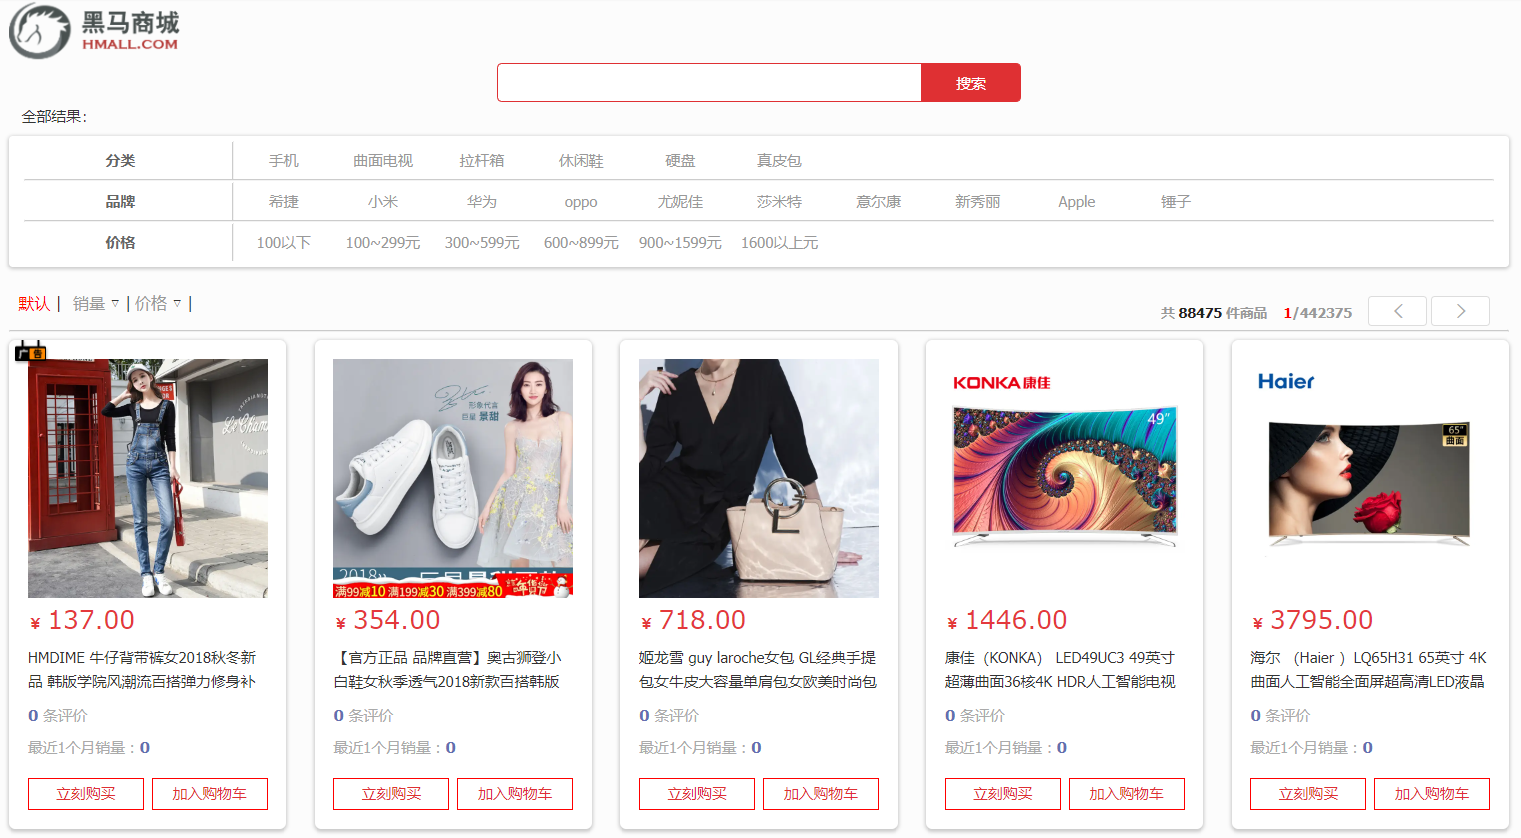

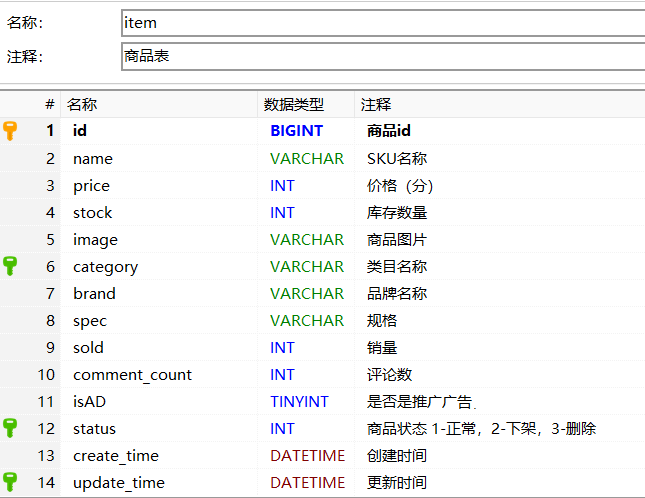

| 数据库字段 | 页面用途 / 同步用途 | 本篇索引设计判断 |
| --- | --- | --- |
| id | 定位与跳转详情 | `keyword`；同时作为 `_id` |
| name | 关键词搜索、标题展示 | `text` + IK |
| price | 价格区间、排序与展示 | `integer`，单位分 |
| category、brand | 精确筛选、展示 | `keyword` |
| sold、comment_count | 排序或展示 | `integer`；comment_count 转为 commentCount |
| isAD | 广告标记 / 条件 | `boolean`，从数据库值显式转换 |
| update_time | 展示或同步核对 | `date`；字段名 updateTime，明确时区 |
| stock | 本示例只展示库存 | `integer`；不建检索与排序结构 |
| image | 展示商品图 | `keyword`；不建检索与排序结构 |
| spec | 商品规格 | 本示例不收入；需规格筛选时另外设计结构 |
| status | 1 正常、2 下架、3 删除 | 导入与同步时决定是否收录 |
| create_time | 业务创建时间 | 本页面不需要时不收入索引 |

价格使用分，避免浮点金额误差；数据库是 INT 时本例用 integer，若业务价格范围更大应改用 long 并同步调整类型。

本篇采用“**索引只保存可上架展示的商品**”的方案。下架或删除时同步删除 ES 文档；若业务选择保留全部状态，则要增加 status 字段，并让所有搜索一致过滤状态。这两种方案应选定一种，不能靠前端临时隐藏来保证结果正确。


## 22. items 的完整 Mapping

课件截图明确展示了 id、name、commentCount、isAD、updateTime 等定义，部分字段折叠。下面是**按商品页面需求补齐的整理方案**；折叠字段的定义、展示字段关闭索引、search_analyzer 和日期格式不是逐字抄录的课件配置。（课件第 49、51 页）

```http
PUT /items
{
  "mappings": {
    "properties": {
      "id": {
        "type": "keyword"
      },
      "name": {
        "type": "text",
        "analyzer": "ik_max_word",
        "search_analyzer": "ik_smart"
      },
      "price": {
        "type": "integer"
      },
      "stock": {
        "type": "integer",
        "index": false,
        "doc_values": false
      },
      "image": {
        "type": "keyword",
        "index": false,
        "doc_values": false
      },
      "category": {
        "type": "keyword"
      },
      "brand": {
        "type": "keyword"
      },
      "sold": {
        "type": "integer"
      },
      "commentCount": {
        "type": "integer"
      },
      "isAD": {
        "type": "boolean"
      },
      "updateTime": {
        "type": "date",
        "format": "strict_date_optional_time||epoch_millis"
      }
    }
  }
}
```

price、category、brand、sold 等保留可检索结构及默认 doc_values，支持条件检索与适用的排序 / 聚合。name 用于全文匹配；本例没有按名称排序的需求，因此不添加 keyword 多字段。

stock 当前只展示，因此关闭 index 和 doc_values。以后若需要“仅看有货商品”，要重新评估其 Mapping；不能在该方案中直接把 stock 当作检索条件。image 的关闭配置也不影响从 `_source` 返回图片地址。


## 23. Java 客户端版本与 Maven 依赖

REST 接口可以被不同语言调用；Java 客户端把请求与响应封装成对象，减少手写 HTTP 和解析工作的重复。（课件第 46—47 页）

| 客户端 | 本章边界 |
| --- | --- |
| Java Low Level REST Client | 负责较底层的 HTTP 通信 |
| RestHighLevelClient | 课程使用的 7.12.1 高级客户端，提供 Request / Response |
| Java API Client | 后续客户端路线，类名与调用方式不同，不能直接混用本章代码 |

官方说明 High Level REST Client **自 7.15.0 起弃用**，推荐 Java API Client。本章为了理解课件保留 7.12.1；新项目应根据实际 ES 版本选择受支持的客户端。

**Maven 整理示例**，只展示本章客户端依赖，其他业务 / Spring 依赖由项目提供：

```xml
<project xmlns="http://maven.apache.org/POM/4.0.0"
         xmlns:xsi="http://www.w3.org/2001/XMLSchema-instance"
         xsi:schemaLocation="http://maven.apache.org/POM/4.0.0 https://maven.apache.org/xsd/maven-4.0.0.xsd">
  <modelVersion>4.0.0</modelVersion>
  <groupId>com.example</groupId>
  <artifactId>es-learning</artifactId>
  <version>1.0.0</version>
  <properties>
    <maven.compiler.source>8</maven.compiler.source>
    <maven.compiler.target>8</maven.compiler.target>
    <elasticsearch.version>7.12.1</elasticsearch.version>
  </properties>
  <dependencies>
    <dependency>
      <groupId>org.elasticsearch.client</groupId>
      <artifactId>elasticsearch-rest-high-level-client</artifactId>
      <version>${elasticsearch.version}</version>
    </dependency>
  </dependencies>
</project>
```

课件通过 `<elasticsearch.version>7.12.1</elasticsearch.version>` 覆盖父工程依赖管理中的版本，并称 Spring Boot 默认版本为 7.17.0。该默认值属于课件当时的父 POM 情境，不能推广到全部 Boot 版本；day08 资料没有据此核对到完整工程 POM。

接入现有 Boot 工程时检查 effective POM 与 dependency tree，确保 ES 核心库、低级客户端、高级客户端没有被不同依赖管理规则混成不兼容版本。只修改一个 jar 的版本并不能保证整条依赖一致。


## 24. 初始化与关闭 RestHighLevelClient

客户端管理 HTTP 连接资源，应复用而非每次请求都创建。（课件第 47 页）

**Java 8 整理示例**：

```java
import java.io.IOException;
import org.apache.http.HttpHost;
import org.elasticsearch.client.RestClient;
import org.elasticsearch.client.RestHighLevelClient;

public class EsClientExample {
    public static void main(String[] args) throws IOException {
        String address = "http://192.168.150.101:9200";
        try (RestHighLevelClient client = new RestHighLevelClient(
                RestClient.builder(HttpHost.create(address)))) {
            System.out.println(
                client.ping(org.elasticsearch.client.RequestOptions.DEFAULT)
            );
        }
    }
}
```

地址是课件示例，要改为运行 Java 程序的机器能够访问的 ES 地址。容器中的 localhost 指当前容器；不能把它自动当作另一个容器或宿主机。

该示例适合独立验证连接，try-with-resources 在结束时关闭客户端。Spring 应用中通常创建单例 Bean，并在容器关闭时调用 close；不要在某次业务请求结束后关闭全局客户端。

课程示例使用 HTTP。实际连接方式、认证与 TLS 应按目标集群配置；Kibana 页面能打开也不等于 Java 进程能访问 ES。


## 25. Java 索引库 API

索引操作遵循“创建 Request → 准备参数 → 调用 indices API → 处理响应”。（课件第 51—53 页）

| REST | Request | 调用 |
| --- | --- | --- |
| `PUT /items` | CreateIndexRequest | `client.indices().create(...)` |
| `GET /items` | GetIndexRequest | `client.indices().get(...)` |
| `HEAD /items` | GetIndexRequest | `client.indices().exists(...)` |
| `DELETE /items` | DeleteIndexRequest | `client.indices().delete(...)` |

以下类展示四种操作。调用 create 前，将第 22 节 HTTP 请求的 **JSON 请求体**保存到示例工程 `src/main/resources/es/items.json`；文件中不包含 `PUT /items` 这一行。

```java
import java.io.IOException;
import java.nio.charset.StandardCharsets;
import java.nio.file.Files;
import java.nio.file.Paths;
import org.elasticsearch.action.admin.indices.delete.DeleteIndexRequest;
import org.elasticsearch.client.RequestOptions;
import org.elasticsearch.client.RestHighLevelClient;
import org.elasticsearch.client.indices.CreateIndexRequest;
import org.elasticsearch.client.indices.GetIndexRequest;
import org.elasticsearch.client.indices.GetIndexResponse;
import org.elasticsearch.common.xcontent.XContentType;

public class ItemIndexOperations {
    public static void create(RestHighLevelClient client) throws IOException {
        String mapping = new String(
            Files.readAllBytes(Paths.get("src/main/resources/es/items.json")),
            StandardCharsets.UTF_8
        );
        CreateIndexRequest request = new CreateIndexRequest("items");
        request.source(mapping, XContentType.JSON);
        client.indices().create(request, RequestOptions.DEFAULT);
    }

    public static GetIndexResponse get(RestHighLevelClient client)
            throws IOException {
        return client.indices().get(
            new GetIndexRequest("items"), RequestOptions.DEFAULT
        );
    }

    public static boolean exists(RestHighLevelClient client)
            throws IOException {
        return client.indices().exists(
            new GetIndexRequest("items"), RequestOptions.DEFAULT
        );
    }

    public static void delete(RestHighLevelClient client) throws IOException {
        client.indices().delete(
            new DeleteIndexRequest("items"), RequestOptions.DEFAULT
        );
    }
}
```

`request.source(...)` 接收完整建索引 JSON，含外层 `mappings`。课件的 `MAPPING_TEMPLATE` 也是这段 JSON 的字符串形式。本例读取文件是为了在 Java 8 中避免很长的转义字符串；相对路径读取仅适合从示例工程根目录运行的演示，打包应用应改为读取 classpath 资源。

exists 查询成功不代表之后创建一定成功，两个调用之间仍可能有其他进程创建索引。索引初始化应由明确的迁移 / 初始化流程负责，不能在每条商品写入之前重复创建。


## 26. Java 文档 CRUD

文档操作直接调用客户端的 index、get、update、delete；这些接口与 `client.indices()` 的索引库操作属于不同层级。（课件第 55—59 页）

| 操作 | Request | 关键参数 |
| --- | --- | --- |
| 新增 / 全量替换 | IndexRequest | 索引、ID、完整 JSON |
| 按 ID 查询 | GetRequest | 索引、ID |
| 局部更新 | UpdateRequest | 索引、ID、doc |
| 删除文档 | DeleteRequest | 索引、ID |

```java
import java.io.IOException;
import java.util.Map;
import org.elasticsearch.action.delete.DeleteRequest;
import org.elasticsearch.action.delete.DeleteResponse;
import org.elasticsearch.action.get.GetRequest;
import org.elasticsearch.action.get.GetResponse;
import org.elasticsearch.action.index.IndexRequest;
import org.elasticsearch.action.index.IndexResponse;
import org.elasticsearch.action.update.UpdateRequest;
import org.elasticsearch.action.update.UpdateResponse;
import org.elasticsearch.client.RequestOptions;
import org.elasticsearch.client.RestHighLevelClient;
import org.elasticsearch.common.xcontent.XContentType;

public class ItemDocumentOperations {
    public static IndexResponse index(RestHighLevelClient client,
                                      String id, String json)
            throws IOException {
        IndexRequest request = new IndexRequest("items").id(id);
        request.source(json, XContentType.JSON);
        return client.index(request, RequestOptions.DEFAULT);
    }

    public static Map<String, Object> get(RestHighLevelClient client,
                                          String id) throws IOException {
        GetResponse response = client.get(
            new GetRequest("items", id), RequestOptions.DEFAULT
        );
        if (!response.isExists()) {
            return null;
        }
        System.out.println(response.getSourceAsString());
        return response.getSourceAsMap();
    }

    public static UpdateResponse updatePriceAndStock(
            RestHighLevelClient client, String id, int priceFen, int stock)
            throws IOException {
        UpdateRequest request = new UpdateRequest("items", id);
        request.doc("price", priceFen, "stock", stock);
        return client.update(request, RequestOptions.DEFAULT);
    }

    public static DeleteResponse delete(RestHighLevelClient client,
                                         String id) throws IOException {
        return client.delete(
            new DeleteRequest("items", id), RequestOptions.DEFAULT
        );
    }
}
```

`UpdateRequest.doc(...)` 中每两个参数构成一组字段名与值。价格参数 `priceFen` 表明单位是分，避免调用方把 3499 元直接当成 3499 分。

GET 先调用 `isExists()` 再解析；`getSourceAsString()` 得到原始 JSON，`getSourceAsMap()` 得到 Map。返回 null 在本示例中表示文档不存在，接口层可转为 404；网络异常不应吞掉后当作“没有数据”。

业务需要类型化 ItemDoc 时，使用项目的 JSON 工具反序列化，并让字段名、布尔值、时间格式与 Mapping 一致。再次提交同 ID 的 IndexRequest 是全量替换，不是默认局部更新。


## 27. 商品文档与类型转换

数据库字段与搜索文档字段必须显式对齐；错误单位、日期或字段名会造成“请求成功但业务含义错误”。（根据课件商品表整理）

**与第 22 节 Mapping 一致的完整商品示例**：

```json
{
  "id": "1001",
  "name": "小米手机",
  "price": 349900,
  "stock": 20,
  "image": "/images/items/1001.png",
  "category": "手机",
  "brand": "小米",
  "sold": 1200,
  "commentCount": 350,
  "isAD": false,
  "updateTime": "2026-10-09T02:00:00Z"
}
```

写入该 JSON 时，IndexRequest 的 `id` 同样使用 `"1001"`，才能把业务 ID 与 ES 文档 ID 按约定保持一致。

| 数据库 → 文档 | 转换规则 |
| --- | --- |
| BIGINT id → 字符串 id / `_id` | 保留原始 ID，不先转成可能丢精度的浮点数 |
| INT price → integer price | 原本就是分，不再乘 100；展示时才转换成元 |
| comment_count → commentCount | 显式改名；避免两种名称同时出现 |
| TINYINT isAD → boolean | 按业务约定将 0 / 1 映射为 false / true，其他值按异常规则处理 |
| DATETIME update_time → date updateTime | 数据库值通常不带时区，先明确业务时区再序列化 |
| status → 是否写入 | 本例仅正常状态写入，下架 / 删除同步移除 |

**补充：业务时间为上海时区的转换示例**：

```java
import java.time.LocalDateTime;
import java.time.ZoneId;

LocalDateTime databaseTime = LocalDateTime.of(2026, 10, 9, 10, 0);
String updateTime = databaseTime
    .atZone(ZoneId.of("Asia/Shanghai"))
    .toInstant()
    .toString();
// 结果为 2026-10-09T02:00:00Z
```

不能把没有时区的本地时间字符串直接加 Z；Z 表示 UTC，错误标记会让实际时间相差 8 小时。转换前还应明确数据库与 JDBC 的时间处理规则，避免对已经转换过的时间重复转换。

stock 来自搜索副本，只适合本方案的展示。最终购买和扣减库存仍调用库存 / 交易服务确认当前状态。


## 28. Java BulkRequest 与逐项检查

BulkRequest 封装多个普通写请求，Java 客户端负责生成 NDJSON，不需要手工拼接换行。（课件第 61—63 页）

下面是**有限批次的商品全量写入示例**。入参中的每个 Map 均采用第 27 节字段结构；调用者先把全量数据分成小批次。

```java
import java.io.IOException;
import java.util.ArrayList;
import java.util.List;
import java.util.Map;
import org.elasticsearch.action.bulk.BulkItemResponse;
import org.elasticsearch.action.bulk.BulkRequest;
import org.elasticsearch.action.bulk.BulkResponse;
import org.elasticsearch.action.index.IndexRequest;
import org.elasticsearch.client.RequestOptions;
import org.elasticsearch.client.RestHighLevelClient;

public class ItemBulkOperations {
    public static List<Map<String, Object>> indexBatch(
            RestHighLevelClient client,
            List<Map<String, Object>> documents) throws IOException {
        List<Map<String, Object>> failed = new ArrayList<>();
        if (documents.isEmpty()) {
            return failed;
        }

        BulkRequest request = new BulkRequest();
        for (Map<String, Object> document : documents) {
            Object idValue = document.get("id");
            if (idValue == null || idValue.toString().trim().isEmpty()) {
                throw new IllegalArgumentException("商品文档缺少 id");
            }
            String id = idValue.toString();
            request.add(new IndexRequest("items").id(id).source(document));
        }

        BulkResponse response = client.bulk(request, RequestOptions.DEFAULT);
        if (response.hasFailures()) {
            for (BulkItemResponse item : response.getItems()) {
                if (item.isFailed()) {
                    System.err.println(
                        "id=" + item.getId()
                        + ", status=" + item.status()
                        + ", reason=" + item.getFailureMessage()
                    );
                    failed.add(documents.get(item.getItemId()));
                }
            }
        }
        return failed;
    }
}
```

`getItemId()` 是该项在本批中的位置，不是业务商品 ID；这里用它找回失败的原始文档。返回的失败集合供调用方记录与分类处理，**不是允许不加判断地无限重试**。

课件用 `source("json source", XContentType.JSON)` 表示占位，本篇改用实际 Map 数据，避免把占位字符串当成合法商品 JSON。BulkRequest 也可添加 DeleteRequest、UpdateRequest；混合动作时应同时保存动作类型与上下文。

若 `client.bulk(...)` 抛出网络异常，未拿到响应就无法按 items 判断每项结果；调用方需按第 20 节处理未知执行状态。日志中的完整文档是否记录，也应由项目日志策略决定。


## 29. 全量导入与增量同步

商品数据库与 ES 分别写入，天然存在失败窗口。ES 搜索数据是可重建的查询投影，必须有初始化、增量更新和修复路径。（工程补充，可连接前两章 MQ）

```text
初始化：
MySQL 正常商品 → 分页读取 → 转为搜索文档 → 小批量 Bulk → 核对结果

增量：
商品事务提交 → 可靠变更事件 → MQ → 消费者读取 / 构造商品新状态
                                         ├── 正常：写入同 _id
                                         └── 下架 / 删除：删除同 _id
```

| 环节 | 必须解决的问题 |
| --- | --- |
| 全量导入 | 避免一次加载所有商品；逐项记录失败并核对 ID |
| 数据库事务与事件发送 | 需要可靠发布机制，例如事务发件箱与补偿 |
| MQ 重投 | 同 ID 幂等定位；确认 ES 操作完成后再按策略 ACK |
| 事件乱序 | 业务版本 / 顺序保证，或读取最新状态；避免过期写回 |
| 全量与增量并行 | 使用明确的变更水位、回放或版本方案，避免漏变化 |
| 修复 | 定期对账、补偿失败商品、必要时重建索引 |

“同 ID 写入”不能解决所有一致性问题。尤其删除后，旧的更新事件可能把商品重新写出来；重建期间也可能用旧快照覆盖新状态。事件设计应覆盖更新与删除的顺序和版本。

没有分布式事务的这条链路通常保证**最终一致性**：短时间搜索结果可能滞后，系统通过可靠事件和补偿收敛。搜索投影不承担库存原子扣减等交易职责。


## 30. 验证顺序与常见问题

在自己的匹配版本环境中，先检查分词和 Mapping，再检查文档和批量结果；不要一开始只看搜索页面。（本篇没有执行这些服务端检查）

**基础检查请求**：

```http
GET /items/_mapping
```

```http
POST /items/_analyze
{
  "field": "name",
  "text": "小米手机"
}
```

```http
GET /items/_doc/1001
```

```http
GET /items/_count
```

| 验证项 / 现象 | 预期或排查方向 |
| --- | --- |
| 创建索引提示 unknown analyzer | IK 是否匹配版本、安装到正确目录并加载到节点 |
| Mapping 中价格是字符串 | 显式创建 integer 字段；已有错误类型通常需新索引 |
| 一次写入后只有少数字段 | 是否误用全量替换上传了局部 JSON |
| email / image 无法当查询条件 | 是否设置 index:false；按 7.12 的边界处理 |
| GET 已变化，搜索 / count 尚未变化 | 检查 refresh 与近实时可见性 |
| 更新时间偏移 8 小时 | 是否把本地时间错误标成 UTC 或重复转时区 |
| Bulk 返回 200 但商品缺失 | 检查 errors、items 与每项失败信息 |
| 插件目录存在但调用失败 | 检查插件加载、版本、目录层级与节点日志 |
| Java 类不存在或出现 NoSuchMethodError | 检查 import 包名与 Maven 实际依赖版本 |
| 下架商品仍出现 | 检查删除事件、失败重试、乱序与搜索刷新 |

count 相同并不能证明商品完全一致，需抽样核对 ID、价格、状态与更新时间；重建时还要检查搜索词的实际命中。创建、完整写入、局部更新、同 ID 替换和删除应分别验证，明确它们的行为差异。


## 31. 核心回顾与面试提示

| 要判断的点 | 核心结论 |
| --- | --- |
| 为什么全文检索快 | 根据词条直接定位候选文档，避免逐条读取全文判断 |
| 分词器做什么 | 写入与搜索时把文本转成词条，不决定 AND / OR |
| text 与 keyword | 前者全文分析，后者精确值；由字段用途决定 |
| index:false | 不建立该字段检索结构；不等于删除 `_source` 或关闭 doc_values |
| Mapping 改类型 | 已有字段类型通常需重建；新增字段等变更可以支持 |
| `_doc/ID` 与 `_update/ID` | 前者全量写入，后者局部合并；同 ID 写入可覆盖 |
| 索引与文档删除 | `DELETE /items` 删除整个集合；`DELETE /items/_doc/ID` 删除一条 |
| Bulk | NDJSON、多动作、逐项结果；不提供跨文档回滚 |
| Java API | Request → 参数 → client 调用 → 响应检查 |
| 搜索数据同步 | 稳定 ID、版本 / 顺序、可靠事件、补偿和重建 |

**面试提示**：解释倒排索引时，从“词条 → 文档 ID”的数据结构出发，再说明查询词的并集、交集与评分是不同环节。解释更新时指出同 ID 的 index 操作会全量替换，而 update 会合并字段后重新索引。解释批量导入时必须提到逐项失败、有限批次、未知执行结果与幂等边界。解释 MySQL 与 ES 协作时说明 ES 是搜索投影，可靠 MQ、顺序 / 版本检查与补偿共同支撑最终一致性。

补充核对来源（访问日期：2026-10-09）：

- [ES 7.12：index 参数](https://www.elastic.co/guide/en/elasticsearch/reference/7.12/mapping-index.html)
- [ES 7.12：doc_values](https://www.elastic.co/guide/en/elasticsearch/reference/7.12/doc-values.html)
- [ES 7.12：Bulk API](https://www.elastic.co/guide/en/elasticsearch/reference/7.12/docs-bulk.html)
- [Java High Level REST Client：7.15.0 起弃用说明](https://www.elastic.co/guide/en/elasticsearch/client/java-rest/7.17/java-rest-high.html)
